# Lab 8 Tasks: Clustering and Regionalization

**Total: 10 points.** Work in this notebook. Answer every question in a markdown cell directly under the task. Submit the notebook with all outputs showing.

Use the same data as the walkthrough (588 Dallas County tracts, ACS 2020-2024). Every map needs a legend. Fix `random_state=42` so results match the answer key.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

gdf = gpd.read_file("data/dallas_tracts_acs2024.gpkg")
import sys, sklearn, matplotlib, geopandas
print(sys.version.split()[0], "| geopandas", geopandas.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print(gdf.shape, gdf.crs.to_string())
gdf.head(3)

/tmp/ipykernel_937/452090800.py:3: DeprecationWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas still uses PyGEOS by default. However, starting with version 0.14, the default will switch to Shapely. To force to use Shapely 2.0 now, you can either uninstall PyGEOS or set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In the next release, GeoPandas will switch to using Shapely by default, even if PyGEOS is installed. If you only have PyGEOS installed to get speed-ups, this switch should be smooth. However, if you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  import geopandas as gpd


3.8.16 | geopandas 0.13.2 | scikit-learn 1.2.2 | matplotlib 3.7.1
(588, 14) EPSG:32614


,GEOID,ALAND,median_house_value,pct_white,pct_hispanic,pct_rented,pct_hh_female,pct_bachelor,median_no_rooms,income_gini,median_age,tt_work,pop_total,geometry
0,48113016638,3449205,420300.0,25.518572,20.501688,65.842167,29.681979,40.048251,4.2,0.4374,48.6,27.664307,2073,"POLYGON ((698187.943 3613912.546, 698236.775 3..."
1,48113013630,292256,230700.0,28.083751,25.261721,86.579491,7.226428,51.539339,3.4,0.3641,36.0,22.172211,2197,"POLYGON ((704710.975 3647157.896, 704727.317 3..."
2,48113012211,1318895,347400.0,7.373370,50.844197,81.978994,20.840243,14.305085,3.7,0.4906,29.8,32.690247,4679,"POLYGON ((715528.594 3631921.330, 715633.903 3..."


In [2]:
VARS = ["median_house_value", "pct_white", "pct_hispanic", "pct_rented", "pct_hh_female",
        "pct_bachelor", "median_no_rooms", "income_gini", "median_age", "tt_work"]
gdf[VARS].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
median_house_value,588.0,391175.18,298977.20,30400.00,224875.00,289700.00,437725.00,2000001.00
pct_white,588.0,29.35,24.28,0.00,10.63,20.90,44.58,94.63
pct_hispanic,588.0,40.00,25.28,0.64,19.01,33.79,62.27,98.41
pct_rented,588.0,42.36,25.74,0.00,21.42,38.23,61.65,98.04
pct_hh_female,588.0,14.92,9.52,0.00,7.34,13.97,20.72,59.19
pct_bachelor,588.0,36.54,25.41,1.58,14.64,29.74,55.94,95.37
median_no_rooms,588.0,5.37,1.37,2.30,4.40,5.30,6.10,10.00
income_gini,588.0,0.41,0.07,0.23,0.36,0.40,0.46,0.68
median_age,588.0,36.06,6.52,19.00,31.48,35.30,40.00,61.60
tt_work,588.0,26.58,5.17,13.41,22.75,26.30,29.92,41.77


In [3]:
PALETTE = ["#7C3AED", "#DB2777", "#2563EB", "#6B6478", "#059669",
           "#F59E0B", "#0EA5E9", "#84CC16", "#EF4444", "#14B8A6"]
COLOR_NAMES = ["purple", "magenta", "blue", "gray", "green",
               "amber", "sky", "lime", "red", "teal"]


def map_clusters(labels, ax, title):
    """Categorical map with one legend entry per cluster (number and color)."""
    labels = np.asarray(labels)
    gdf.plot(color=[PALETTE[i % len(PALETTE)] for i in labels], ax=ax, edgecolor="white", linewidth=0.2)
    ax.set_axis_off()
    ax.set_title(title)
    handles = [Patch(color=PALETTE[i % len(PALETTE)], label=f"{i} ({COLOR_NAMES[i % len(COLOR_NAMES)]})")
               for i in sorted(set(labels))]
    ax.legend(handles=handles, title="Cluster", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)


def ipq(geoms):
    """Isoperimetric quotient: 4 * pi * area / perimeter^2 (1 = circle)."""
    return 4 * np.pi * geoms.area / geoms.length ** 2

In [4]:
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_mutual_info_score
from libpysal import weights
from scipy.sparse.csgraph import connected_components

w = weights.Queen.from_dataframe(gdf, use_index=False)

## Task 1 (20 points)


Map two variables of your choice with `scheme="quantiles"` and `k=5`, side by side, each with a legend that shows class limits. Then answer: which pair of variables in the data do you expect to be most alike on a map, and which least alike? Say why in one sentence each.

In [5]:
# your code here

### ✅ Solution

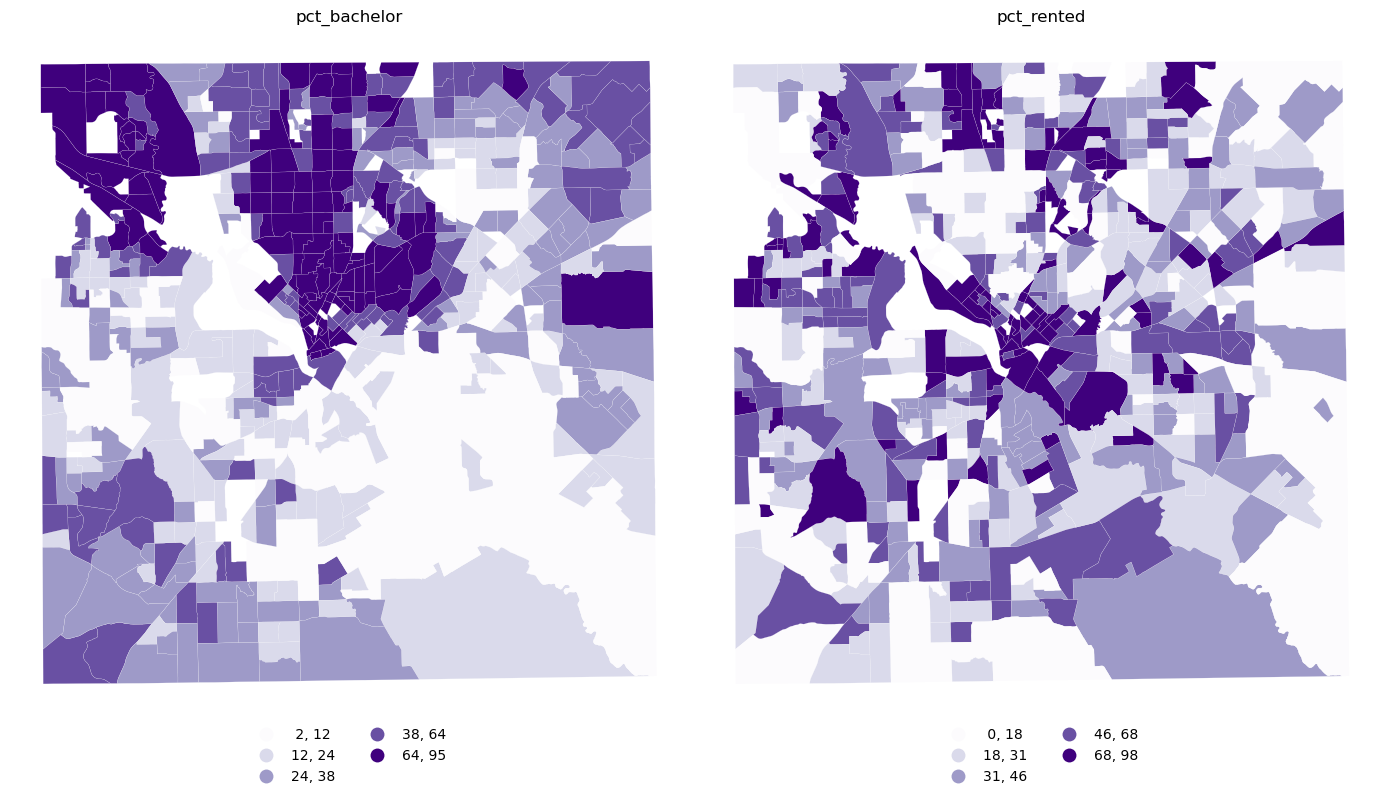

-0.01


In [6]:
pair = ["pct_bachelor", "pct_rented"]
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, v in zip(axes, pair):
    gdf.plot(column=v, scheme="quantiles", k=5, cmap="Purples", legend=True, ax=ax, edgecolor="white", linewidth=0.1,
             legend_kwds={"loc": "upper center", "bbox_to_anchor": (0.5, 0.0), "ncol": 2, "fmt": "{:.0f}", "frameon": False})
    ax.set_axis_off()
    ax.set_title(v)
plt.tight_layout()
plt.show()
print(gdf[VARS].corr().round(2).loc[pair[0], pair[1]])

**Answers:** Any pair is acceptable if the maps have legends and the reasoning is sound. For the example pair, `pct_bachelor` and `pct_rented` have a correlation of -0.01, so their maps share almost nothing. `pct_bachelor` and `pct_white` (0.81) or `median_house_value` (0.73) are expected to look alike. Full credit needs one alike pair and one unlike pair, each with a reason.

## Task 2 (20 points)


Choose four variables that describe one theme, such as housing or social composition, and name the theme. Scale them with `RobustScaler` and run `KMeans` with `n_clusters=4`, `n_init=10`, `random_state=42`. Then:

1. Map the clusters with `map_clusters`.
2. Build a profile table with the mean of each of your variables, the number of tracts, and the percent of land area per cluster.
3. Give each cluster a short name, referring to it by number and color.

In [7]:
# your code here

### ✅ Solution

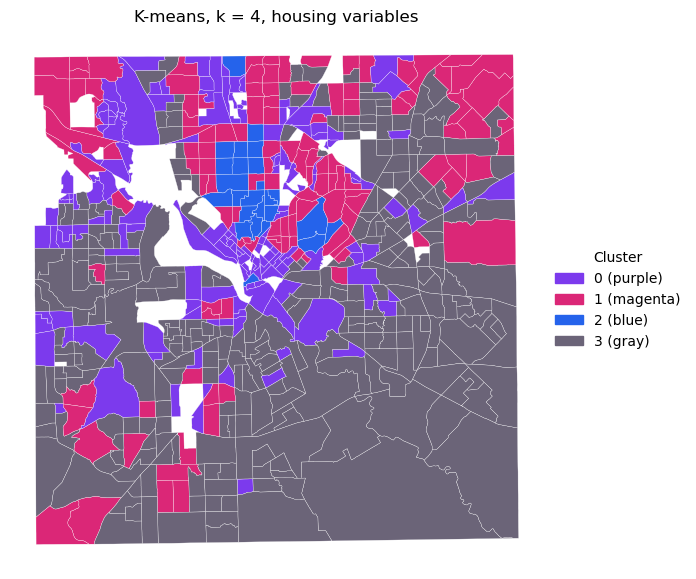

,n_tracts,pct_land,median_house_value,pct_rented,median_no_rooms,median_age
km4,,,,,,
0,158,15.9,370793.7,76.6,3.8,32.2
1,125,20.5,528854.4,24.1,6.5,42.5
2,25,2.9,1497936.2,22.5,7.7,44.1
3,280,60.7,242394.3,33.0,5.5,34.7


In [8]:
theme = ["median_house_value", "pct_rented", "median_no_rooms", "median_age"]     # housing theme
X4 = RobustScaler().fit_transform(gdf[theme])
gdf["km4"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X4)

fig, ax = plt.subplots(figsize=(8, 7))
map_clusters(gdf["km4"], ax, "K-means, k = 4, housing variables")
plt.show()

prof = gdf.groupby("km4")[theme].mean().round(1)
prof.insert(0, "n_tracts", gdf.groupby("km4").size())
prof.insert(1, "pct_land", (100 * gdf.groupby("km4").ALAND.sum() / gdf.ALAND.sum()).round(1))
prof

**Answers:** Grading looks for a map with a legend, a profile table with the three required columns, and names that match the table (for example, "purple, cluster 0: expensive, large, owner-occupied"). Names must refer to the cluster number and color. Results depend on the chosen variables.

## Task 3 (20 points)


For your four variables from Task 3, compute the silhouette score for k = 2 to 8 and plot it. State which k you would use and give one reason that is not the score.

In [9]:
# your code here

### ✅ Solution

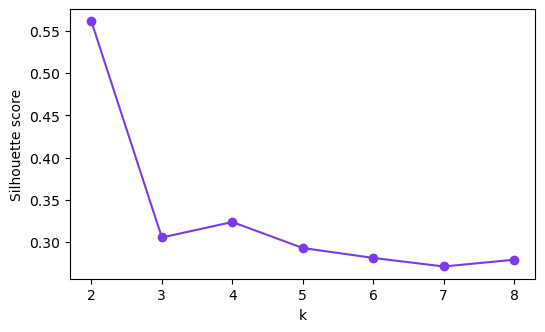

{2: 0.561, 3: 0.305, 4: 0.324, 5: 0.293, 6: 0.281, 7: 0.271, 8: 0.279}

In [10]:
ks = list(range(2, 9))
sil = [silhouette_score(X4, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X4)) for k in ks]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, sil, marker="o", color="#7C3AED")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette score")
plt.show()
dict(zip(ks, np.round(sil, 3)))

**Answers:** Often k = 2 scores highest because it splits the data into the two broadest groups. Accept any k with a purpose-based reason, such as the number of groups a planner can act on, or a k whose clusters have interpretable profiles.

## Task 4 (20 points)


**Open-ended.** A city wants (a) a set of neighborhood types for a housing survey and (b) six emergency-response zones. For each, say whether you would use a cluster or a region, name two variables you would use, and give one risk of your choice. Write four to six sentences.

In [11]:
# your answer goes in a markdown cell below

### ✅ Solution

In [12]:
# (no code)

**Answers:** (a) Clusters: locations that are far apart may share a type, and the goal is to profile types. Variables: income Gini and percent renters. (b) Regions: each zone needs one connected area and one responsible station. Variables: population (equal workload) and road distance, plus compactness. Risks: for (a), cluster names can label a neighborhood unfairly; for (b), tracts with a large margin of error give unstable estimates. Grade on a clear choice per case with a reason tied to connectedness.